# Task 0: Ensure Everything is working

In [23]:
import pandas as pd
import os
from IPython.display import display
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
data_path = "adult_census.csv"

if os.path.exists("../data/adult_census.csv"):
    data_path = "../data/adult_census.csv"

elif os.path.exists("data/adult_census.csv"):
    data_path = "data/adult_census.csv"

df = pd.read_csv(data_path)

display(df.head())
display(df.tail())

rows, cols = df.shape
print(f"Rows: {rows}, Columns: {cols}")

print()
print("Raw Features:")
print(df.columns)

target = "income"
print()
print("Target:")
print(target)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32560,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


Rows: 32561, Columns: 15

Raw Features:
Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='str')

Target:
income


# Task 1: Exploratory Data Analysis (EDA)


Cleaned Features:
Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'sex',
       'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
       'income'],
      dtype='str')


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,0
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,0
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,0
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,0
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,0


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,0
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,0
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,1
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,0
32560,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,0


income
0    0.75919
1    0.24081
Name: proportion, dtype: float64

                Missing Count  Percentage (%)
occupation               1843            5.66
workclass                1836            5.64
native_country            583            1.79


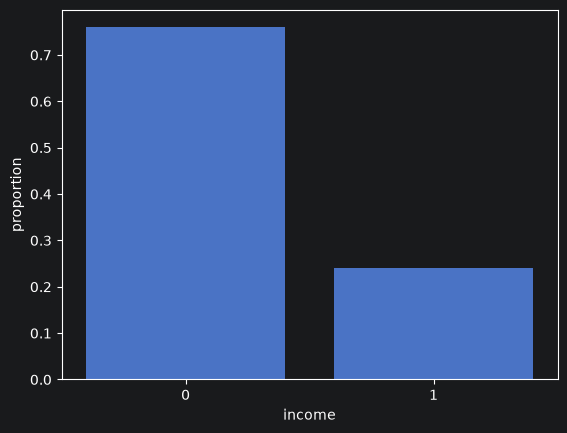

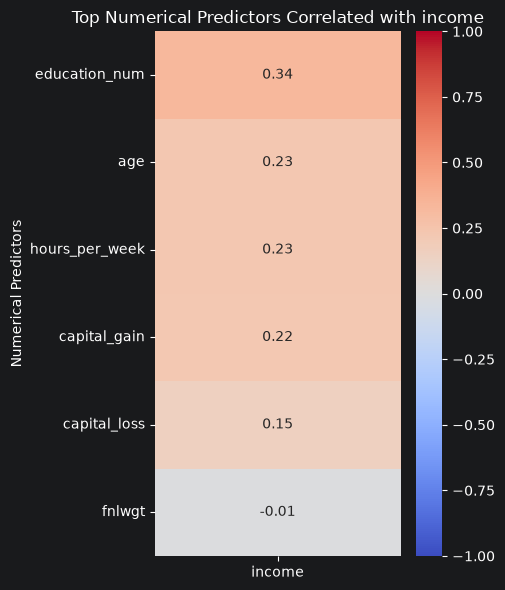

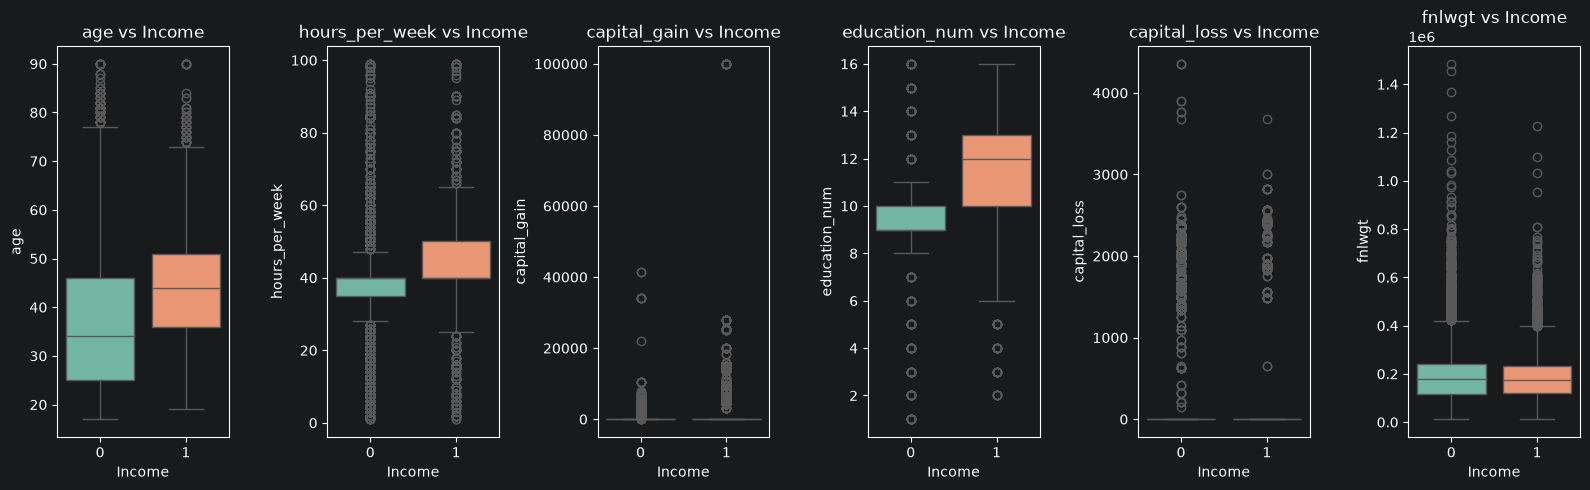

In [11]:
df.columns = df.columns.str.replace('.', '_', regex=False)
print()
print("Cleaned Features:")
print(df.columns)

df[target] = df[target].replace({
    r'(?i)^\s*<=50k\.?\s*$': 0,
    r'(?i)^\s*>50k\.?\s*$': 1
}, regex=True)
df = df.replace(r'^\s*\?\s*$', np.nan, regex=True)
df['income'] = pd.to_numeric(df['income'], errors='coerce')

display(df.head())
display(df.tail())

sns.countplot(x=target, data=df, stat="proportion")
print(df[target].value_counts(normalize=True))

missing_count = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)

print()

missing_df = pd.DataFrame({
    'Missing Count': missing_count[missing_count > 0],
    'Percentage (%)': missing_percent[missing_percent > 0]
})

missing_df = missing_df.sort_values(by='Missing Count', ascending=False)

print(missing_df)

pearson_coeff = df.corr(method='pearson', numeric_only=True)


# 2. Get correlation with target, drop the target itself, and sort by magnitude
top_corr = (
    pearson_coeff[[target]]
    .drop(index=target)                               # Don't predict income with income
    .sort_values(by=target, ascending=False)          # Sort top to bottom
    .head(10)                                         # Ensure top 10 limit is respected
)

plt.figure(figsize=(5, 6))
sns.heatmap(top_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title(f'Top Numerical Predictors Correlated with {target}')
plt.ylabel('Numerical Predictors')
plt.tight_layout()
plt.show()

# Key continuous features to inspect (adjust names to match your cleaned columns)
num_features = ['age', 'hours_per_week', 'capital_gain', 'education_num', 'capital_loss','fnlwgt',]

# Create subplots side-by-side
fig, axes = plt.subplots(1, len(num_features), figsize=(16, 5))

for i, col in enumerate(num_features):
    sns.boxplot(data=df, x=target, y=col, ax=axes[i], palette='Set2', hue=target, legend=False)
    axes[i].set_title(f'{col} vs Income')
    axes[i].set_xlabel('Income')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

# Task 2: Data Preprocessing & Pipeline Construction

In [12]:
X = df.drop(columns=[target])
y = df[target]

# display(X.head())
# display(y)

cat_features = [
    'workclass',
    'education',
    'marital_status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'native_country'
]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_pipeline, num_features),
    ('cat', categorical_pipeline, cat_features),
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


# Task 3: Model Training & Hyperparameter Tuning


In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

log_reg = LogisticRegression(penalty='l2', max_iter=1000, random_state=42)

log_reg_grid = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
}

grid_log_reg = GridSearchCV(
    estimator=log_reg,
    param_grid=log_reg_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)
grid_log_reg.fit(X_train_processed, y_train)
print(f"Best LogReg Params: {grid_log_reg.best_params_}")
print(f"Best LogReg ROC-AUC: {grid_log_reg.best_score_:.4f}\n")
print()



Best LogReg Params: {'C': 1.0}
Best LogReg ROC-AUC: 0.9058




C:\Users\Carter\PycharmProjects\MLAssignment-4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [17]:
rf = RandomForestClassifier(n_estimators=300, random_state=42)

rf_grid = {
    'max_depth': [5, 10, 15, None],
    'min_samples_leaf': [1, 5, 10],
    'max_features': ['sqrt', 0.5]
}

grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=rf_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_rf.fit(X_train_processed, y_train)
print(f"Best RF Params: {grid_rf.best_params_}")
print(f"Best RF ROC-AUC: {grid_rf.best_score_:.4f}\n")
print()



Best RF Params: {'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 5}
Best RF ROC-AUC: 0.9172




In [18]:
gb = GradientBoostingClassifier(random_state=42)

gb_grid = {
    'learning_rate': [0.01, 0.1],       # Shrinkage
    'max_depth': [1, 2, 3],             # Interaction depth d
    'n_estimators': [100, 300]          # Number of trees B
}

grid_gb = GridSearchCV(
    estimator=gb,
    param_grid=gb_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_gb.fit(X_train_processed, y_train)
print(f"Best GB Params: {grid_gb.best_params_}")
print(f"Best GB ROC-AUC: {grid_gb.best_score_:.4f}\n")
print()


Best GB Params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}
Best GB ROC-AUC: 0.9272




In [19]:
svc = SVC(probability=True, random_state=42)

svc_grid = [
    # RBF kernel with C and gamma
    {
        'kernel': ['rbf'],
        'C': [0.1, 1.0, 10.0],
        'gamma': ['scale', 0.01, 0.1]
    },
    # Linear kernel with C
    {
        'kernel': ['linear'],
        'C': [0.1, 1.0, 10.0]
    }
]

grid_svc = GridSearchCV(
    estimator=svc,
    param_grid=svc_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_svc.fit(X_train_processed, y_train)
print(f"Best SVM Params: {grid_svc.best_params_}")
print(f"Best SVM ROC-AUC: {grid_svc.best_score_:.4f}\n")

Training SVM (this may take several minutes)...


C:\Users\Carter\PycharmProjects\MLAssignment-4\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best SVM Params: {'C': 10.0, 'gamma': 0.01, 'kernel': 'rbf'}
Best SVM ROC-AUC: 0.9075



# Task 4: Model Evaluation, Confusion Matrices & Threshold Tuning

=== Test Set Comparative Summary ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8531,0.7392,0.6020,0.6636,0.9024
Random Forest,0.8621,0.7693,0.6103,0.6807,0.9137
Gradient Boosting,0.8669,0.7736,0.6320,0.6957,0.9210
Support Vector Machine,0.8554,0.7604,0.5829,0.6599,0.9011


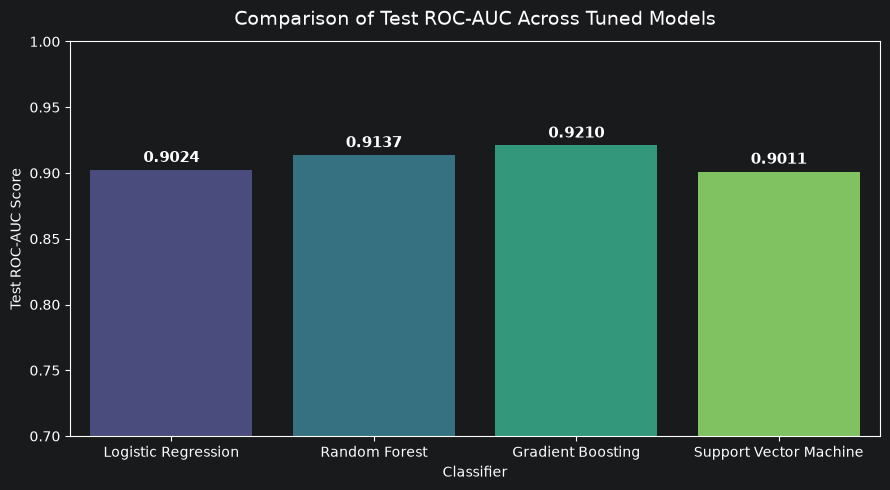

In [21]:
models = {
    'Logistic Regression': grid_log_reg.best_estimator_,
    'Random Forest': grid_rf.best_estimator_,
    'Gradient Boosting': grid_gb.best_estimator_,
    'Support Vector Machine': grid_svc.best_estimator_
}

metrics_list = []

for name, model in models.items():
    # Predictions
    y_pred = model.predict(X_test_processed)
    y_proba = model.predict_proba(X_test_processed)[:, 1]

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    metrics_list.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

# Comparative Summary DataFrame
summary_df = pd.DataFrame(metrics_list).set_index('Model').round(4)
print("=== Test Set Comparative Summary ===")
display(summary_df)

# -------------------------------------------------------------------------
# 2. Seaborn Bar Chart for Test ROC-AUC Scores
# -------------------------------------------------------------------------
plt.figure(figsize=(9, 5))
plot_df = summary_df.reset_index()

ax = sns.barplot(
    data=plot_df,
    x='Model',
    y='ROC-AUC',
    hue='Model',
    palette='viridis',
    legend=False
)
plt.title('Comparison of Test ROC-AUC Across Tuned Models', fontsize=14, pad=12)
plt.ylim(0.7, 1.0)  # Zooms into the meaningful range
plt.ylabel('Test ROC-AUC Score')
plt.xlabel('Classifier')

# Annotate exact scores on top of bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.4f}",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 3),
                textcoords='offset points')

plt.tight_layout()
plt.show()

Best Performing Model: Gradient Boosting


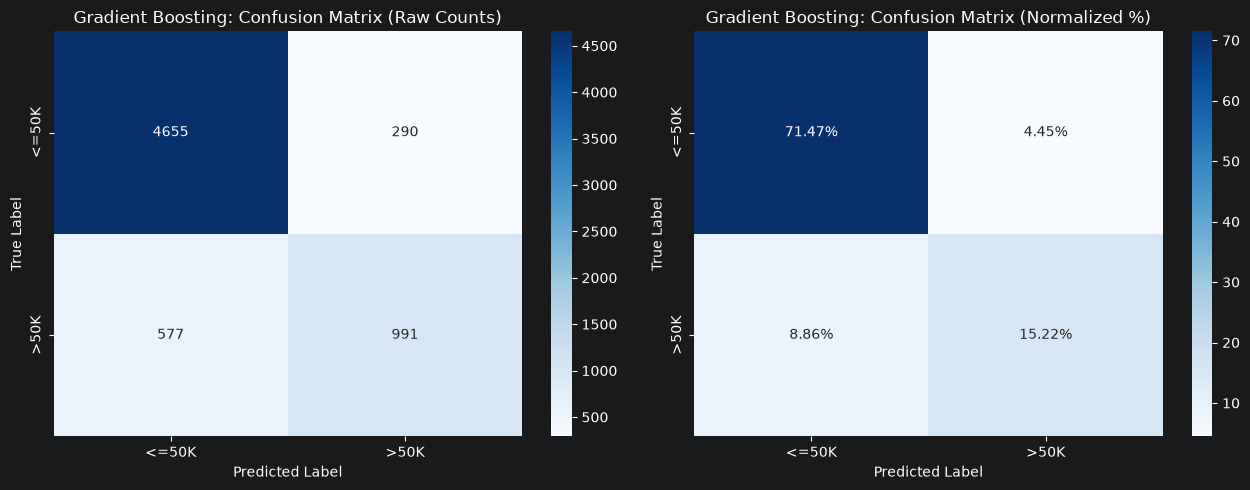

In [22]:
best_model_name = summary_df['ROC-AUC'].idxmax()
best_model = models[best_model_name]
print(f"Best Performing Model: {best_model_name}")

y_pred_best = best_model.predict(X_test_processed)

cm_counts = confusion_matrix(y_test, y_pred_best)
cm_norm = confusion_matrix(y_test, y_pred_best, normalize='all')  # Total percentage

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
class_labels = ['<=50K', '>50K']

sns.heatmap(
    cm_counts,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0],
    xticklabels=class_labels,
    yticklabels=class_labels
)
axes[0].set_title(f'{best_model_name}: Confusion Matrix (Raw Counts)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Heatmap 2: Normalized Percentages
sns.heatmap(
    cm_norm * 100,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    ax=axes[1],
    xticklabels=class_labels,
    yticklabels=class_labels
)
for text in axes[1].texts:
    text.set_text(text.get_text() + '%')

axes[1].set_title(f'{best_model_name}: Confusion Matrix (Normalized %)')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [24]:
oof_probs = cross_val_predict(
    best_model,
    X_train_processed,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

thresholds = np.linspace(0.01, 0.99, 1000)
valid_thresholds = []

for t in thresholds:
    preds = (oof_probs >= t).astype(int)
    rec = recall_score(y_train, preds)
    if rec >= 0.90:
        valid_thresholds.append((t, rec))

t_star, oof_recall = max(valid_thresholds, key=lambda x: x[0])
print(f"Optimal Threshold (t*): {t_star:.4f} (OOF Recall: {oof_recall:.4f})")

y_test_proba = best_model.predict_proba(X_test_processed)[:, 1]

y_test_pred_default = (y_test_proba >= 0.5).astype(int)
prec_05 = precision_score(y_test, y_test_pred_default)
rec_05 = recall_score(y_test, y_test_pred_default)

y_test_pred_custom = (y_test_proba >= t_star).astype(int)
prec_t = precision_score(y_test, y_test_pred_custom)
rec_t = recall_score(y_test, y_test_pred_custom)

threshold_comparison = pd.DataFrame({
    'Metric': ['Threshold (t)', 'Precision', 'Recall'],
    'Default (t = 0.5)': [0.5000, prec_05, rec_05],
    f'Tuned (t = {t_star:.4f})': [t_star, prec_t, rec_t]
}).round(4)

print("\n=== Test Performance: Default vs. Tuned Threshold ===")
display(threshold_comparison)

Optimal Threshold (t*): 0.1846 (OOF Recall: 0.9002)

=== Test Performance: Default vs. Tuned Threshold ===


,Metric,Default (t = 0.5),Tuned (t = 0.1846)
0,Threshold (t),0.5000,0.1846
1,Precision,0.7736,0.5708
2,Recall,0.6320,0.8820
